# CS690A — Assignment 1: Combined Notebook
**Tasks 1.1, 1.2 (scGPT + Geneformer), and Task 2**

This notebook consolidates and cleans up the exploratory work into one runnable pipeline.
Run cells top-to-bottom. Each foundation-model section tries to **load previously saved
embeddings from Drive first**, and only regenerates them (slow, GPU-heavy) if the file
isn't found — so re-running this notebook after a crash/disconnect is cheap.



In [2]:
!pip install -q "pandas>=2.3,<3.1"
!pip install -q scanpy leidenalg python-igraph scikit-learn

from google.colab import drive
drive.mount('/content/drive')

import os, json, time
import numpy as np
import pandas as pd
import scanpy as sc
import anndata as ad
import matplotlib.pyplot as plt

from sklearn.metrics import (
    silhouette_score,
    adjusted_rand_score,
    normalized_mutual_info_score,
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler

sc.settings.verbosity = 1
sc.settings.set_figure_params(dpi=100, facecolor="white")
np.random.seed(0)

ASSIGNMENT_DIR  = "/content/drive/MyDrive/CS690_Assignment 1"
OUT_DIR         = os.path.join(ASSIGNMENT_DIR, "outputs")
os.makedirs(OUT_DIR, exist_ok=True)

DATA_PATH       = os.path.join(ASSIGNMENT_DIR, "dataset_updated.h5ad")
SAMPLE_SUB_PATH = os.path.join(ASSIGNMENT_DIR, "sample_submission.csv")

if not os.path.exists(DATA_PATH):
    DATA_PATH = os.path.join(ASSIGNMENT_DIR, "dataset.h5ad")

print("Assignment dir:", ASSIGNMENT_DIR)
print("Output dir:", OUT_DIR)
print("Using dataset:", DATA_PATH, "| exists:", os.path.exists(DATA_PATH))

adata = sc.read_h5ad(DATA_PATH)
print("\nCells:", adata.n_obs, "| Genes:", adata.n_vars)
print("X range:", float(adata.X.min()), "to", float(adata.X.max()))

NAME = "Nehasri Eragandula"


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.9/10.9 MB 34.6 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.0.5 which is incompatible.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 52.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 60.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.7/5.7 MB 63.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 188.8/188.8 kB 13.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.0/40.0 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.1/79.1 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.7/363.7 kB 11.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━

/tmp/ipykernel_1466/71246199.py:26: FutureWarning: The method set_figure_params is deprecated and will be removed in the future. Use :func:`scanpy.set_figure_params` instead
  sc.settings.set_figure_params(dpi=100, facecolor="white")


Assignment dir: /content/drive/MyDrive/CS690_Assignment 1
Output dir: /content/drive/MyDrive/CS690_Assignment 1/outputs
Using dataset: /content/drive/MyDrive/CS690_Assignment 1/dataset.h5ad | exists: True

Cells: 10727 | Genes: 12303
X range: 0.0 to 7.487774848937988


## Task 1.1 — PCA + Leiden baseline



In [3]:
# ---- QC ----
sc.pp.calculate_qc_metrics(adata, inplace=True)

MIN_GENES, MAX_GENES = 900, 4000
qc_mask = (
    (adata.obs["n_genes_by_counts"] >= MIN_GENES) &
    (adata.obs["n_genes_by_counts"] <= MAX_GENES)
).to_numpy()

adata_qc = adata[qc_mask].copy()
print(f"QC: kept {adata_qc.n_obs} / {adata.n_obs} cells "
      f"({100*adata_qc.n_obs/adata.n_obs:.1f}%)")


QC: kept 10482 / 10727 cells (97.7%)


In [4]:
# ---- Normalization check -----

adata_preprocessed = adata_qc.copy()
print("X range:", float(adata_preprocessed.X.min()), "to", float(adata_preprocessed.X.max()))


X range: 0.0 to 7.464667320251465


In [5]:
# ---- HVG + scale + PCA ----
sc.pp.highly_variable_genes(adata_preprocessed, n_top_genes=2000, flavor="seurat")
adata_hvg = adata_preprocessed[:, adata_preprocessed.var["highly_variable"]].copy()

adata_pca = adata_hvg.copy()
sc.pp.scale(adata_pca, zero_center=True, max_value=10)
sc.tl.pca(adata_pca, n_comps=50, svd_solver="arpack")

print("HVGs:", adata_hvg.n_vars)
print("PCA shape:", adata_pca.obsm["X_pca"].shape)
print("Variance explained (50 PCs):",
      f"{adata_pca.uns['pca']['variance_ratio'].sum()*100:.2f}%")


HVGs: 2000
PCA shape: (10482, 50)
Variance explained (50 PCs): 26.26%


In [6]:
# ---- Neighbors + Leiden resolution sweep ----
sc.pp.neighbors(adata_pca, n_neighbors=15, n_pcs=50, use_rep="X_pca", metric="euclidean")

resolutions = [0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50, 0.60, 0.80, 1.00, 1.20, 1.50, 2.00]
results = []
for res in resolutions:
    key = f"leiden_{res}"
    sc.tl.leiden(adata_pca, resolution=res, key_added=key, random_state=42, flavor="igraph", directed=False)
    labels = adata_pca.obs[key].astype(str).to_numpy()
    n_clusters = len(np.unique(labels))
    sil = silhouette_score(adata_pca.obsm["X_pca"], labels, metric="euclidean") if n_clusters > 1 else np.nan
    results.append({"resolution": res, "n_clusters": n_clusters, "silhouette": sil})

pca_resolution_df = pd.DataFrame(results)
print(pca_resolution_df.to_string(index=False))

best_row = pca_resolution_df.loc[pca_resolution_df["silhouette"].idxmax()]
best_resolution_pca = best_row["resolution"]
print("\nBest resolution (by silhouette):", best_resolution_pca,
      "| clusters:", int(best_row["n_clusters"]),
      "| silhouette:", round(best_row["silhouette"], 4))


 resolution  n_clusters  silhouette
       0.10          11    0.272789
       0.15          12    0.249480
       0.20          14    0.224359
       0.25          15    0.179508
       0.30          15    0.179077
       0.40          16    0.173719
       0.50          20    0.191886
       0.60          20    0.172476
       0.80          22    0.177757
       1.00          22    0.178110
       1.20          24    0.157360
       1.50          26    0.141491
       2.00          31    0.129482

Best resolution (by silhouette): 0.1 | clusters: 11 | silhouette: 0.2728


In [7]:
# ---- Final Leiden clustering at chosen resolution ----
FINAL_RESOLUTION_PCA = float(best_resolution_pca)

sc.tl.leiden(adata_pca, resolution=FINAL_RESOLUTION_PCA, key_added="leiden_final",
             random_state=42, flavor="igraph", directed=False)
adata_pca.obs["leiden_final"] = adata_pca.obs["leiden_final"].astype(str)

pca_final_silhouette = silhouette_score(
    adata_pca.obsm["X_pca"], adata_pca.obs["leiden_final"].to_numpy(), metric="euclidean"
)
print("Final resolution:", FINAL_RESOLUTION_PCA)
print("Number of clusters:", adata_pca.obs["leiden_final"].nunique())
print("Silhouette:", round(pca_final_silhouette, 4))
print("\nCluster sizes:")
print(adata_pca.obs["leiden_final"].value_counts().sort_index())


Final resolution: 0.1
Number of clusters: 11
Silhouette: 0.2728

Cluster sizes:
leiden_final
0     3427
1      201
10      13
2     3228
3      598
4     1511
5     1048
6      362
7       58
8       23
9       13
Name: count, dtype: int64


In [8]:
# ---- Differential expression / marker genes  ----
adata_de = adata_qc.copy()
adata_de.obs["leiden_final"] = adata_pca.obs["leiden_final"].to_numpy()

sc.tl.rank_genes_groups(adata_de, groupby="leiden_final", method="wilcoxon", key_added="rank_genes_final")

result = adata_de.uns["rank_genes_final"]
marker_records = []
for cluster in result["names"].dtype.names:
    genes = result["names"][cluster][:10]
    for rank, gene in enumerate(genes, start=1):
        marker_records.append({"cluster": cluster, "rank": rank, "gene": gene})
marker_df = pd.DataFrame(marker_records)

for cluster in result["names"].dtype.names:
    print(f"\nCluster {cluster}:")
    print(marker_df[marker_df["cluster"] == cluster][["rank", "gene"]].to_string(index=False))



Cluster 0:
 rank   gene
    1   LDHB
    2  RPS29
    3 RPS15A
    4   TPT1
    5  RPS12
    6   RPS3
    7  RPS14
    8  RPS25
    9  RPL36
   10  RPS28

Cluster 1:
 rank     gene
    1     PLD4
    2     CD74
    3      GSN
    4 HLA-DPA1
    5 HLA-DPB1
    6  CCDC88A
    7  HLA-DRA
    8 HLA-DRB1
    9 HLA-DQA2
   10     CST3

Cluster 2:
 rank    gene
    1  S100A9
    2     LYZ
    3  S100A8
    4    MNDA
    5    VCAN
    6 S100A12
    7    FCN1
    8     FOS
    9    CTSS
   10    CD14

Cluster 3:
 rank  gene
    1  GNLY
    2  NKG7
    3  PRF1
    4 KLRD1
    5 KLRF1
    6  CTSW
    7  GZMA
    8  CST7
    9  HOPX
   10  GZMB

Cluster 4:
 rank     gene
    1    CD79A
    2    MS4A1
    3     CD37
    4    CD79B
    5     CD74
    6    BANK1
    7 HLA-DQA1
    8  HLA-DRA
    9 HLA-DQB1
   10 HLA-DPB1

Cluster 5:
 rank  gene
    1  CCL5
    2  NKG7
    3  GZMA
    4 KLRG1
    5  GZMK
    6  CST7
    7  CTSW
    8  IL32
    9 KLRB1
   10  HCST

Cluster 6:
 rank   gene
    1   LST1

In [9]:
# ---- Biological annotation ----
# Assigned from the marker-gene table above (classic PBMC/bone-marrow markers).
cluster_annotations = {
    "0":  "Naive T cells",                                  # ribosomal-high signature (LDHB, RPS29, RPS15A...)
    "1":  "Plasmacytoid Dendritic Cells (pDCs)",             # PLD4, CD74, HLA-DPA1, GSN
    "2":  "Classical Monocytes (CD14+)",                     # LYZ, S100A9, S100A8, FCN1
    "3":  "Natural Killer (NK) cells",                       # GNLY, NKG7, PRF1, KLRD1
    "4":  "B cells",                                         # CD79A, MS4A1, CD79B, BANK1
    "5":  "CD8+ Memory/Effector T cells",                    # CCL5, NKG7, GZMA, GZMK
    "6":  "Non-classical Monocytes (CD16+)",                 # LST1, AIF1, FCER1G, MS4A7
    "7":  "Platelets / Megakaryocytes",                      # PF4, PPBP, NRGN, GNG11
    "8":  "B cells (small subset)",                          # MS4A1, CD79A, RALGPS2
    "9":  "Hematopoietic Stem/Progenitor Cells (HSPCs)",     # CD34, SOX4, CYTL1, PRSS57
    "10": "Plasma cells",                                    # SEC11C, MZB1, SSR4, PDIA4
    "11": "Conventional Dendritic Cells (cDC1)",             # CLEC9A, BATF3, IDO1
}

adata_pca.obs["cell_type"] = adata_pca.obs["leiden_final"].map(cluster_annotations)
print(adata_pca.obs[["leiden_final", "cell_type"]].drop_duplicates().sort_values("leiden_final").to_string(index=False))


leiden_final                                   cell_type
           0                               Naive T cells
           1         Plasmacytoid Dendritic Cells (pDCs)
          10                                Plasma cells
           2                 Classical Monocytes (CD14+)
           3                   Natural Killer (NK) cells
           4                                     B cells
           5                CD8+ Memory/Effector T cells
           6             Non-classical Monocytes (CD16+)
           7                  Platelets / Megakaryocytes
           8                      B cells (small subset)
           9 Hematopoietic Stem/Progenitor Cells (HSPCs)


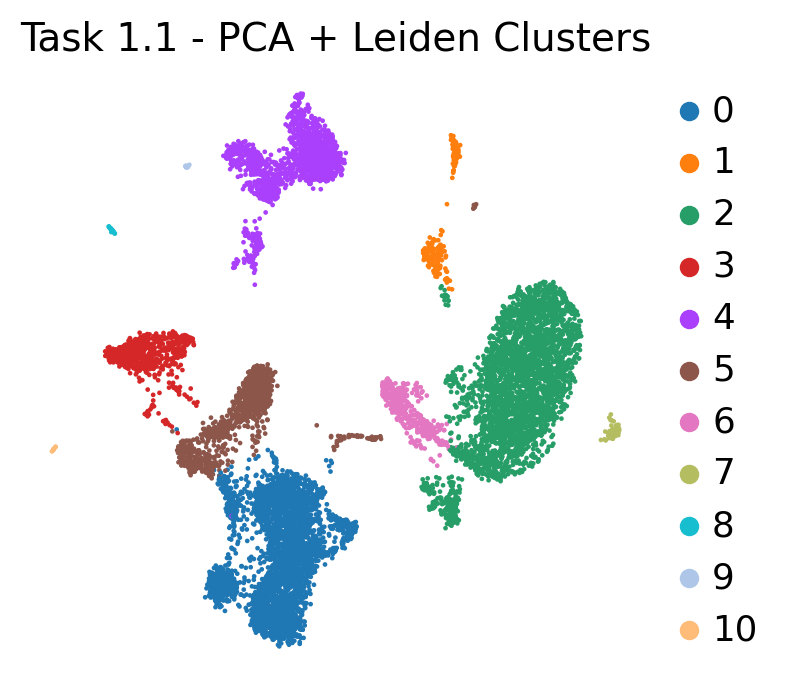

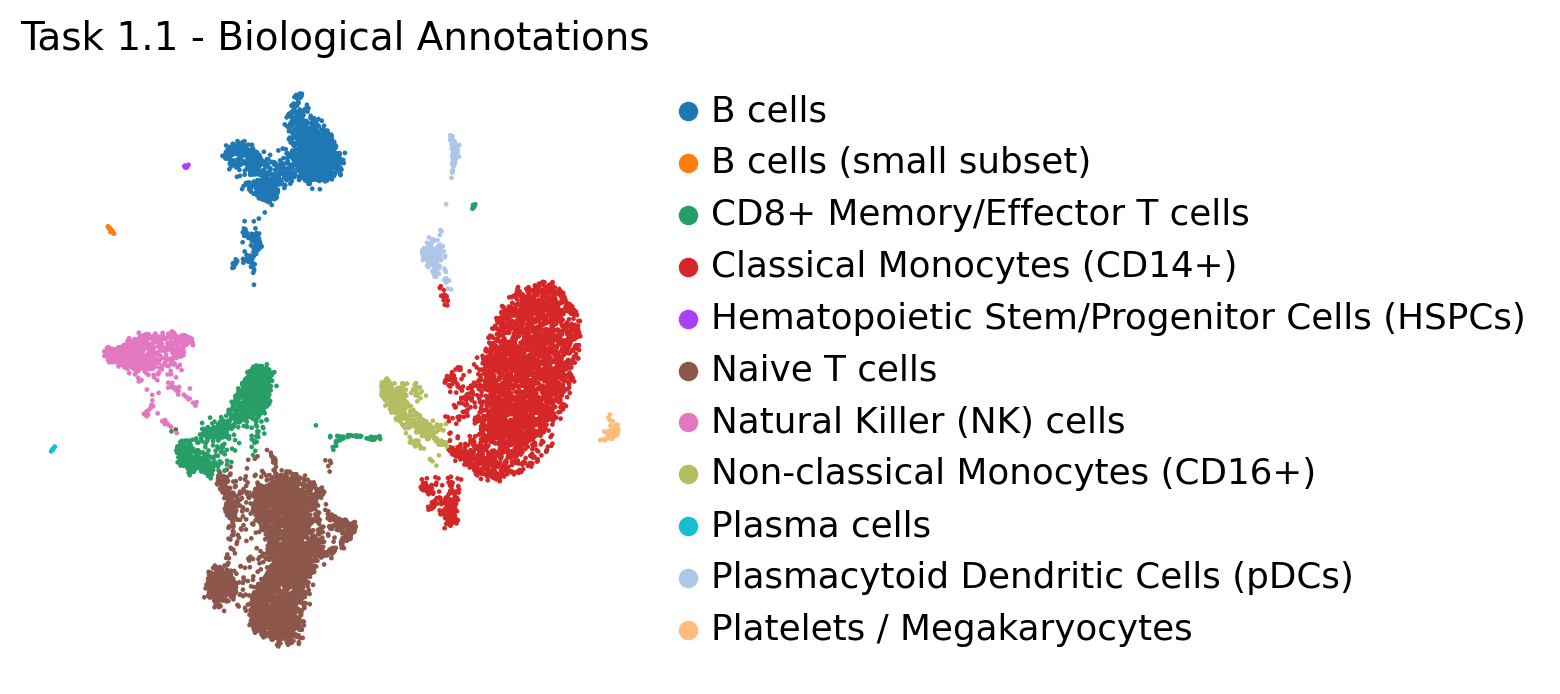

In [10]:
# ---- UMAP + plots ----
sc.tl.umap(adata_pca, min_dist=0.5, spread=1.0, random_state=42)

sc.pl.umap(adata_pca, color="leiden_final", title="Task 1.1 - PCA + Leiden Clusters",
           legend_loc="right margin", frameon=False, show=True)
sc.pl.umap(adata_pca, color="cell_type", title="Task 1.1 - Biological Annotations",
           legend_loc="right margin", frameon=False, show=True)


In [ ]:
# ---- Back-fill labels for QC-dropped cells + build full-length submission ----
# The Kaggle submission needs ALL 10,727 original cells, but adata_pca only has the
# QC-passed subset. We train a KNN on the QC-passed PCA space and predict labels for
# the QC-dropped cells, using the SAME HVGs and the SAME scale (mean/std) as the final PCA.

hvg_genes = adata_hvg.var_names
adata_all_hvg = adata[:, hvg_genes].copy()
X_all = np.asarray(adata_all_hvg.X.todense() if hasattr(adata_all_hvg.X, "todense") else adata_all_hvg.X, dtype=np.float32)

scaler_mean = adata_pca.var["mean"].to_numpy()
scaler_std  = adata_pca.var["std"].to_numpy()
X_all_scaled = (X_all - scaler_mean) / scaler_std
X_all_scaled = np.clip(X_all_scaled, -10, 10)   # matches max_value=10 used in sc.pp.scale

# project into the same PCA space
pca_components = adata_pca.varm["PCs"]     # (n_hvg, 50)
X_all_pca = X_all_scaled @ pca_components

qc_labels = adata_pca.obs["leiden_final"].astype(str).to_numpy()
knn = KNeighborsClassifier(n_neighbors=15, metric="euclidean")
knn.fit(adata_pca.obsm["X_pca"], qc_labels)
all_predicted_labels = knn.predict(X_all_pca)

final_labels_pca_full = np.empty(adata.n_obs, dtype=object)
final_labels_pca_full[qc_mask]  = qc_labels
final_labels_pca_full[~qc_mask] = all_predicted_labels[~qc_mask]

print("QC-passed cells kept exact Leiden label:", qc_mask.sum())
print("QC-dropped cells filled via KNN:", (~qc_mask).sum())
print("Total labeled:", len(final_labels_pca_full), "| Unique clusters:", len(np.unique(final_labels_pca_full)))


QC-passed cells kept exact Leiden label: 10482
QC-dropped cells filled via KNN: 245
Total labeled: 10727 | Unique clusters: 12


In [ ]:
# ---- Save Task 1.1 submission ----
sample_submission = pd.read_csv(SAMPLE_SUB_PATH) if os.path.exists(SAMPLE_SUB_PATH) else pd.DataFrame({"ID": np.arange(adata.n_obs)})

pca_submission = pd.DataFrame({
    "ID": sample_submission["ID"].to_numpy() if "ID" in sample_submission.columns else np.arange(adata.n_obs),
    "Label": final_labels_pca_full.astype(int) + 1,   # 1-based
})

pca_submission_path = os.path.join(ASSIGNMENT_DIR, f"{NAME}_task1_1_submission.csv")
pca_submission.to_csv(pca_submission_path, index=False)
print("Saved:", pca_submission_path)
print(pca_submission.head())


Saved: /content/drive/MyDrive/CS690_Assignment 1/Nehasri Eragandula_task1_1_submission.csv
   ID  Label
0   0      1
1   1      2
2   2      3
3   3      4
4   4      5


## Task 1.2 — Foundation model embeddings (scGPT + Geneformer)


In [ ]:
# ============================================================
# scGPT — load-or-generate
# ============================================================
SCGPT_EMB_PATH = os.path.join(ASSIGNMENT_DIR, "scgpt_cell_embeddings.npy")
SCGPT_DIR      = os.path.join(ASSIGNMENT_DIR, "scGPT_whole_human")

if os.path.exists(SCGPT_EMB_PATH):
    print("Found existing scGPT embeddings, loading...")
    scgpt_embeddings = np.load(SCGPT_EMB_PATH)
    print("Loaded shape:", scgpt_embeddings.shape)
else:
    print("No saved scGPT embeddings found -- regenerating (this needs a GPU).")
    !pip install -q scgpt gdown

    import torch
    from scgpt.model import TransformerModel
    from scgpt.utils import load_pretrained
    from scgpt.tasks.cell_emb import get_batch_cell_embeddings

    os.makedirs(SCGPT_DIR, exist_ok=True)
    vocab_file  = os.path.join(SCGPT_DIR, "vocab.json")
    args_file   = os.path.join(SCGPT_DIR, "args.json")
    model_file  = os.path.join(SCGPT_DIR, "best_model.pt")

    if not (os.path.exists(vocab_file) and os.path.exists(args_file) and os.path.exists(model_file)):
        import gdown
        gdown.download_folder(
            id="1oWh_-ZRdhtoGQ2Fw24HP41FgLoomVo-y",
            output=SCGPT_DIR, quiet=False, use_cookies=False
        )

    class CompatGeneVocab:
        def __init__(self, token2idx):
            self.token2idx = {str(t): int(i) for t, i in token2idx.items()}
            self.idx2token = {i: t for t, i in self.token2idx.items()}

        @classmethod
        def from_file(cls, path):
            with open(path) as f:
                token2idx = json.load(f)
            return cls(token2idx)

        def __len__(self):
            return len(self.token2idx)

        def __contains__(self, token):
            return token in self.token2idx

        def __getitem__(self, token):
            return self.token2idx[token]

        def __call__(self, tokens):
            if isinstance(tokens, (list, tuple)):
                return [self.token2idx[t] for t in tokens]
            return self.token2idx[tokens]

        def append_token(self, token):
            if token not in self.token2idx:
                idx = len(self.token2idx)
                self.token2idx[token] = idx
                self.idx2token[idx] = token

        def get_stoi(self):
            return dict(self.token2idx)

        def get_itos(self):
            return [self.idx2token[i] for i in range(len(self.idx2token))]

        def set_default_index(self, idx):
            self.default_index = idx

    vocab = CompatGeneVocab.from_file(vocab_file)
    for tok in ["<pad>", "<cls>", "<eoc>"]:
        if tok not in vocab:
            vocab.append_token(tok)

    with open(args_file) as f:
        model_configs = json.load(f)

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = TransformerModel(
        len(vocab), model_configs["embsize"], model_configs["nheads"],
        model_configs["d_hid"], model_configs["nlayers"],
        vocab=vocab, pad_value=-2, n_input_bins=model_configs.get("n_bins", 51),
    )
    load_pretrained(model, torch.load(model_file, map_location=device), verbose=False)
    model.to(device).eval()

    adata_scgpt = adata.copy()
    adata_scgpt.var["feature_name"] = adata_scgpt.var_names.tolist()
    matched_genes = [g for g in adata_scgpt.var_names if g in vocab]
    adata_scgpt = adata_scgpt[:, matched_genes].copy()
    gene_ids_scgpt = np.array([vocab[g] for g in adata_scgpt.var["feature_name"]], dtype=int)

    scgpt_embeddings = get_batch_cell_embeddings(
        adata_scgpt, cell_embedding_mode="cls", model=model, vocab=vocab,
        max_length=model_configs["max_seq_len"], batch_size=32,
        model_configs=model_configs, gene_ids=gene_ids_scgpt, use_batch_labels=False,
    )
    np.save(SCGPT_EMB_PATH, scgpt_embeddings)
    print("Generated + saved scGPT embeddings:", scgpt_embeddings.shape)

Found existing scGPT embeddings, loading...
Loaded shape: (10727, 512)


In [ ]:
# ---- scGPT clustering ----
adata_scgpt_emb = sc.AnnData(X=scgpt_embeddings)
adata_scgpt_emb.obs_names = adata.obs_names.copy()

sc.pp.neighbors(adata_scgpt_emb, n_neighbors=15, use_rep="X", metric="euclidean")

resolutions = [0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50, 0.60, 0.80, 1.00]
scgpt_res_results = []
for res in resolutions:
    key = f"leiden_{res}"
    sc.tl.leiden(adata_scgpt_emb, resolution=res, key_added=key, random_state=42, flavor="igraph", directed=False)
    labels = adata_scgpt_emb.obs[key].astype(str).to_numpy()
    n_clusters = len(np.unique(labels))
    sil = silhouette_score(adata_scgpt_emb.X, labels, metric="euclidean") if n_clusters > 1 else np.nan
    scgpt_res_results.append({"resolution": res, "n_clusters": n_clusters, "silhouette": sil})

scgpt_resolution_df = pd.DataFrame(scgpt_res_results)
print(scgpt_resolution_df.to_string(index=False))

best_scgpt_res = scgpt_resolution_df.loc[scgpt_resolution_df["silhouette"].idxmax(), "resolution"]
sc.tl.leiden(adata_scgpt_emb, resolution=float(best_scgpt_res), key_added="leiden_scgpt_final",
             random_state=42, flavor="igraph", directed=False)
adata_scgpt_emb.obs["leiden_scgpt_final"] = adata_scgpt_emb.obs["leiden_scgpt_final"].astype(str)

scgpt_silhouette = silhouette_score(
    adata_scgpt_emb.X, adata_scgpt_emb.obs["leiden_scgpt_final"].to_numpy(), metric="euclidean"
)
print("\nFinal scGPT resolution:", best_scgpt_res,
      "| clusters:", adata_scgpt_emb.obs["leiden_scgpt_final"].nunique(),
      "| silhouette:", round(scgpt_silhouette, 4))


 resolution  n_clusters  silhouette
       0.10           9    0.341261
       0.15           9    0.353978
       0.20          12    0.278374
       0.25          12    0.277600
       0.30          13    0.282676
       0.40          15    0.273450
       0.50          15    0.277660
       0.60          17    0.268304
       0.80          20    0.212225
       1.00          22    0.204078

Final scGPT resolution: 0.15 | clusters: 9 | silhouette: 0.354


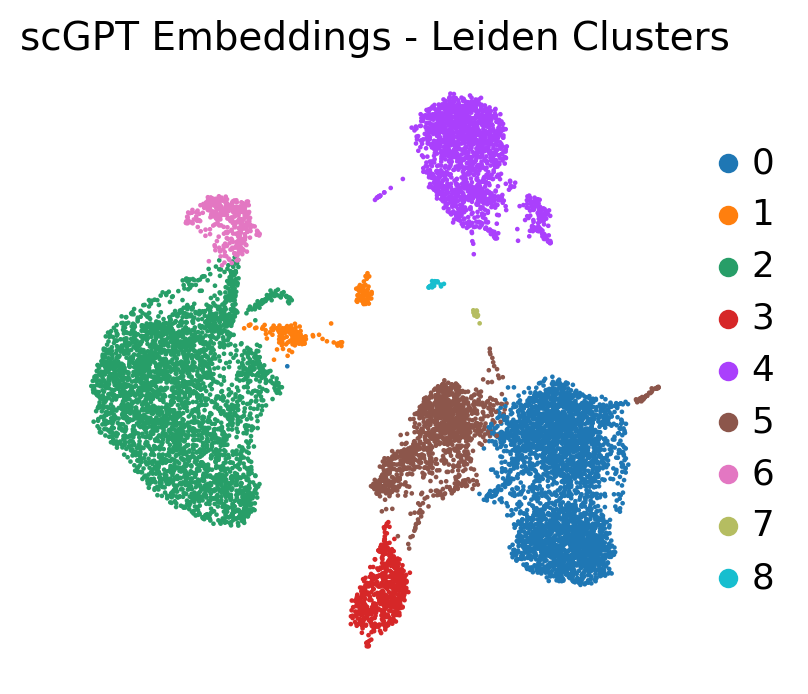

Saved: /content/drive/MyDrive/CS690_Assignment 1/Nehasri Eragandula_task1_2_scgpt_submission.csv


In [ ]:
# ---- scGPT UMAP + submission ----
sc.tl.umap(adata_scgpt_emb, min_dist=0.5, spread=1.0, random_state=42)
sc.pl.umap(adata_scgpt_emb, color="leiden_scgpt_final", title="scGPT Embeddings - Leiden Clusters",
           legend_loc="right margin", frameon=False, show=True)

scgpt_labels_1based = adata_scgpt_emb.obs["leiden_scgpt_final"].astype(int).to_numpy() + 1
scgpt_submission = pd.DataFrame({"ID": np.arange(adata.n_obs), "Label": scgpt_labels_1based})
scgpt_submission_path = os.path.join(ASSIGNMENT_DIR, f"{NAME}_task1_2_scgpt_submission.csv")
scgpt_submission.to_csv(scgpt_submission_path, index=False)
print("Saved:", scgpt_submission_path)


In [ ]:
GENEFORMER_EMB_PATH = os.path.join(ASSIGNMENT_DIR, "task1_2_geneformer_embeddings.npy")
GENEFORMER_PARTIAL_PATH = GENEFORMER_EMB_PATH + ".partial.npz"
GENEFORMER_DIR = os.path.join(ASSIGNMENT_DIR, "Geneformer")

if os.path.exists(GENEFORMER_EMB_PATH):
    print("Found existing Geneformer embeddings, loading...")
    geneformer_embeddings = np.load(GENEFORMER_EMB_PATH)
    print("Loaded shape:", geneformer_embeddings.shape)
else:
    print("Regenerating Geneformer embeddings...")
    import torch, pickle, sys
    from torch.nn.utils.rnn import pad_sequence
    from torch.utils.data import Dataset, DataLoader
    from transformers import BertForMaskedLM
    from tqdm.auto import tqdm

    # Skip re-clone if it already exists
    if not os.path.exists(GENEFORMER_DIR):
        !git clone https://huggingface.co/ctheodoris/Geneformer "$GENEFORMER_DIR"

    MODEL_DIR = os.path.join(GENEFORMER_DIR, "Geneformer-V2-104M")
    sys.path.insert(0, GENEFORMER_DIR)

    with open(os.path.join(GENEFORMER_DIR, "geneformer", "token_dictionary_gc104M.pkl"), "rb") as f:
        token_dictionary = pickle.load(f)
    with open(os.path.join(GENEFORMER_DIR, "geneformer", "gene_name_id_dict_gc104M.pkl"), "rb") as f:
        gene_name_id_dict = pickle.load(f)

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    geneformer_model = BertForMaskedLM.from_pretrained(MODEL_DIR, output_hidden_states=True, output_attentions=False)
    geneformer_model.to(device).eval()

    CLS_TOKEN = token_dictionary["<cls>"]
    PAD_TOKEN = token_dictionary["<pad>"]

    X_dense = np.asarray(adata.X.todense() if hasattr(adata.X, "todense") else adata.X)
    gene_names = adata.var_names.tolist()
    ensembl_ids = [gene_name_id_dict.get(g) for g in gene_names]
    valid_gene_idx = [i for i, eid in enumerate(ensembl_ids) if eid in token_dictionary]
    valid_tokens = np.array([token_dictionary[ensembl_ids[i]] for i in valid_gene_idx])

    geneformer_sequences = []
    for row in X_dense:
        expr = row[valid_gene_idx]
        order = np.argsort(-expr)
        order = order[expr[order] > 0]
        seq = [CLS_TOKEN] + valid_tokens[order][:2047].tolist()
        geneformer_sequences.append(seq)

    class GFDataset(Dataset):
        def __init__(self, seqs): self.seqs = seqs
        def __len__(self): return len(self.seqs)
        def __getitem__(self, i): return torch.tensor(self.seqs[i], dtype=torch.long)

    def collate(batch):
        input_ids = pad_sequence(batch, batch_first=True, padding_value=PAD_TOKEN)
        attention_mask = (input_ids != PAD_TOKEN).long()
        return {"input_ids": input_ids, "attention_mask": attention_mask}

    BATCH_SIZE = 8
    loader = DataLoader(GFDataset(geneformer_sequences), batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate)

    embedding_dim = geneformer_model.config.hidden_size
    geneformer_embeddings = np.zeros((adata.n_obs, embedding_dim), dtype=np.float32)

    # Resume from a partial checkpoint if one exists
    start_idx = 0
    if os.path.exists(GENEFORMER_PARTIAL_PATH):
        partial = np.load(GENEFORMER_PARTIAL_PATH)
        saved = partial["embeddings"]
        start_idx = int(partial["idx"])
        geneformer_embeddings[:start_idx] = saved[:start_idx]
        print(f"Resuming from checkpoint at cell {start_idx}/{adata.n_obs}")

    batches_to_skip = start_idx // BATCH_SIZE

    with torch.no_grad():
        idx = start_idx
        for b, batch in enumerate(tqdm(loader, desc="Geneformer embeddings")):
            if b < batches_to_skip:
                continue
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            outputs = geneformer_model(input_ids=input_ids, attention_mask=attention_mask)
            hidden = outputs.hidden_states[-2]
            cls_emb = hidden[:, 0, :].cpu().numpy().astype(np.float32)
            geneformer_embeddings[idx: idx + cls_emb.shape[0]] = cls_emb
            idx += cls_emb.shape[0]

            if b % 100 == 0:
                np.savez(GENEFORMER_PARTIAL_PATH, embeddings=geneformer_embeddings, idx=idx)

    np.save(GENEFORMER_EMB_PATH, geneformer_embeddings)
    if os.path.exists(GENEFORMER_PARTIAL_PATH):
        os.remove(GENEFORMER_PARTIAL_PATH)
    print("Generated + saved Geneformer embeddings:", geneformer_embeddings.shape)

Regenerating Geneformer embeddings...


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Resuming from checkpoint at cell 8/10727


Geneformer embeddings:   0%|          | 0/1341 [00:00<?, ?it/s]

Generated + saved Geneformer embeddings: (10727, 768)


In [ ]:
# ---- Geneformer clustering ----
from sklearn.preprocessing import normalize as sk_normalize
geneformer_embeddings_norm = sk_normalize(geneformer_embeddings)

adata_geneformer = sc.AnnData(X=geneformer_embeddings_norm)
adata_geneformer.obs_names = adata.obs_names.astype(str)
adata_geneformer.obsm["X_geneformer"] = geneformer_embeddings_norm

sc.pp.neighbors(adata_geneformer, n_neighbors=15, use_rep="X_geneformer", metric="cosine")

resolutions = [0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50, 0.60, 0.80, 1.00]
gf_res_results = []
for res in resolutions:
    key = f"leiden_r{str(res).replace('.', '_')}"
    sc.tl.leiden(adata_geneformer, resolution=res, key_added=key, random_state=42, flavor="igraph", directed=False)
    labels = adata_geneformer.obs[key].astype(str).to_numpy()
    n_clusters = len(np.unique(labels))
    sil = silhouette_score(adata_geneformer.obsm["X_geneformer"], labels, metric="cosine") if n_clusters > 1 else np.nan
    gf_res_results.append({"resolution": res, "n_clusters": n_clusters, "silhouette": sil})

gf_resolution_df = pd.DataFrame(gf_res_results)
print(gf_resolution_df.to_string(index=False))

best_gf_res = gf_resolution_df.loc[gf_resolution_df["silhouette"].idxmax(), "resolution"]
sc.tl.leiden(adata_geneformer, resolution=float(best_gf_res), key_added="leiden_geneformer_final",
             random_state=42, flavor="igraph", directed=False)
adata_geneformer.obs["leiden_geneformer_final"] = adata_geneformer.obs["leiden_geneformer_final"].astype(str)

geneformer_silhouette = silhouette_score(
    adata_geneformer.obsm["X_geneformer"],
    adata_geneformer.obs["leiden_geneformer_final"].to_numpy(), metric="cosine"
)
print("\nFinal Geneformer resolution:", best_gf_res,
      "| clusters:", adata_geneformer.obs["leiden_geneformer_final"].nunique(),
      "| silhouette:", round(geneformer_silhouette, 4))


 resolution  n_clusters  silhouette
       0.10           9    0.168265
       0.15           9    0.190555
       0.20          10    0.186208
       0.25          12    0.211254
       0.30          12    0.214670
       0.40          13    0.209328
       0.50          14    0.207267
       0.60          14    0.207858
       0.80          17    0.146292
       1.00          17    0.146585

Final Geneformer resolution: 0.3 | clusters: 12 | silhouette: 0.2147


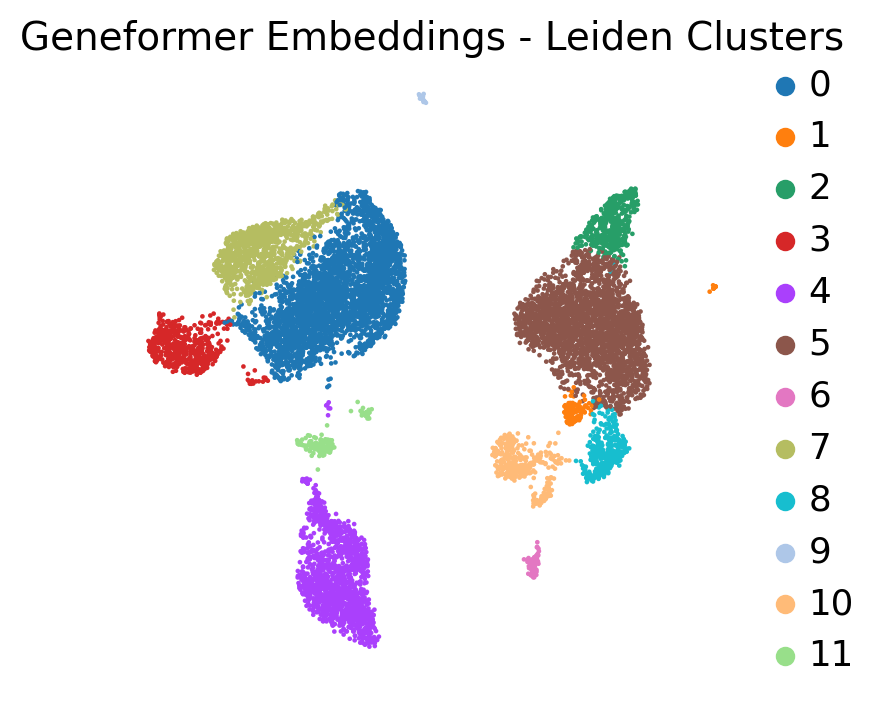

Saved: /content/drive/MyDrive/CS690_Assignment 1/Nehasri Eragandula_task1_2_geneformer_submission.csv


In [ ]:
# ---- Geneformer UMAP + submission ----
sc.tl.umap(adata_geneformer, min_dist=0.5, spread=1.0, random_state=42)
sc.pl.umap(adata_geneformer, color="leiden_geneformer_final", title="Geneformer Embeddings - Leiden Clusters",
           legend_loc="right margin", frameon=False, show=True)

geneformer_labels_1based = adata_geneformer.obs["leiden_geneformer_final"].astype(int).to_numpy() + 1
geneformer_submission = pd.DataFrame({"ID": np.arange(adata.n_obs), "Label": geneformer_labels_1based})
geneformer_submission_path = os.path.join(ASSIGNMENT_DIR, f"{NAME}_task1_2_geneformer_submission.csv")
geneformer_submission.to_csv(geneformer_submission_path, index=False)
print("Saved:", geneformer_submission_path)


## Task 1.2 — Comparison table (PCA vs scGPT vs Geneformer)



In [ ]:
pca_labels_full   = final_labels_pca_full.astype(int)
scgpt_labels_full = adata_scgpt_emb.obs["leiden_scgpt_final"].astype(int).to_numpy()
gf_labels_full    = adata_geneformer.obs["leiden_geneformer_final"].astype(int).to_numpy()

pairs = [
    ("PCA vs scGPT", pca_labels_full, scgpt_labels_full),
    ("PCA vs Geneformer", pca_labels_full, gf_labels_full),
    ("scGPT vs Geneformer", scgpt_labels_full, gf_labels_full),
]

comparison_rows = []
for name, a, b in pairs:
    comparison_rows.append({
        "comparison": name,
        "ARI": adjusted_rand_score(a, b),
        "NMI": normalized_mutual_info_score(a, b),
    })
comparison_df = pd.DataFrame(comparison_rows)

silhouette_summary = pd.DataFrame({
    "representation": ["PCA", "scGPT", "Geneformer"],
    "n_clusters": [len(np.unique(pca_labels_full)), len(np.unique(scgpt_labels_full)), len(np.unique(gf_labels_full))],
    "silhouette": [pca_final_silhouette, scgpt_silhouette, geneformer_silhouette],
})

print("========== PAIRWISE ARI / NMI ==========")
print(comparison_df.to_string(index=False))
print("\n========== SILHOUETTE SUMMARY (label-free) ==========")
print(silhouette_summary.to_string(index=False))

comparison_df.to_csv(os.path.join(ASSIGNMENT_DIR, f"{NAME}_task1_2_pairwise_comparison.csv"), index=False)
silhouette_summary.to_csv(os.path.join(ASSIGNMENT_DIR, f"{NAME}_task1_2_silhouette_summary.csv"), index=False)


========== PAIRWISE ARI / NMI ==========
         comparison      ARI      NMI
       PCA vs scGPT 0.892748 0.879883
  PCA vs Geneformer 0.873246 0.855804
scGPT vs Geneformer 0.821009 0.845811

========== SILHOUETTE SUMMARY (label-free) ==========
representation  n_clusters  silhouette
           PCA          12    0.249495
         scGPT           9    0.353978
    Geneformer          12    0.214670


## Task 2 — Combined pipeline (PCA + scGPT + Geneformer)



In [ ]:
from sklearn.decomposition import PCA as SKPCA

N_DIMS_PCA = 15
N_DIMS_SCGPT = 45

def reduce_block(X, n_dims):
    n_dims = min(n_dims, X.shape[1])
    return SKPCA(n_components=n_dims, random_state=42).fit_transform(X)

pca_block   = StandardScaler().fit_transform(X_all_pca)
scgpt_block = StandardScaler().fit_transform(scgpt_embeddings)

pca_block_r   = reduce_block(pca_block, N_DIMS_PCA)
scgpt_block_r = reduce_block(scgpt_block, N_DIMS_SCGPT)

combined = np.concatenate([pca_block_r, scgpt_block_r], axis=1)

print("Combined shape:", combined.shape)

Combined shape: (10727, 60)


In [ ]:
# ---- Reduce combined space, then cluster ----
from sklearn.decomposition import PCA as SKPCA

n_reduce = min(50, combined.shape[1] - 1)
combined_reduced = SKPCA(n_components=n_reduce, random_state=42).fit_transform(combined)
print("Reduced combined shape:", combined_reduced.shape)

adata_combined = sc.AnnData(X=combined_reduced)
adata_combined.obs_names = adata.obs_names.astype(str)

sc.pp.neighbors(adata_combined, n_neighbors=15, use_rep="X", metric="euclidean")

resolutions = [0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50, 0.60, 0.80, 1.00, 1.20]
combined_res_results = []
for res in resolutions:
    key = f"leiden_{res}"
    sc.tl.leiden(adata_combined, resolution=res, key_added=key, random_state=42, flavor="igraph", directed=False)
    labels = adata_combined.obs[key].astype(str).to_numpy()
    n_clusters = len(np.unique(labels))
    sil = silhouette_score(combined_reduced, labels, metric="euclidean") if n_clusters > 1 else np.nan
    combined_res_results.append({"resolution": res, "n_clusters": n_clusters, "silhouette": sil})

combined_resolution_df = pd.DataFrame(combined_res_results)
print(combined_resolution_df.to_string(index=False))

best_combined_res = combined_resolution_df.loc[combined_resolution_df["silhouette"].idxmax(), "resolution"]
sc.tl.leiden(adata_combined, resolution=float(best_combined_res), key_added="leiden_combined_final",
             random_state=42, flavor="igraph", directed=False)
adata_combined.obs["leiden_combined_final"] = adata_combined.obs["leiden_combined_final"].astype(str)

combined_silhouette = silhouette_score(
    combined_reduced, adata_combined.obs["leiden_combined_final"].to_numpy(), metric="euclidean"
)
print("\nFinal combined resolution:", best_combined_res,
      "| clusters:", adata_combined.obs["leiden_combined_final"].nunique(),
      "| silhouette:", round(combined_silhouette, 4))


Reduced combined shape: (10727, 50)
 resolution  n_clusters  silhouette
       0.10           9    0.322587
       0.15           9    0.327161
       0.20          11    0.315193
       0.25          12    0.267026
       0.30          13    0.261530
       0.40          17    0.261710
       0.50          17    0.255859
       0.60          18    0.247613
       0.80          21    0.233917
       1.00          22    0.219309
       1.20          24    0.194415

Final combined resolution: 0.15 | clusters: 9 | silhouette: 0.3272


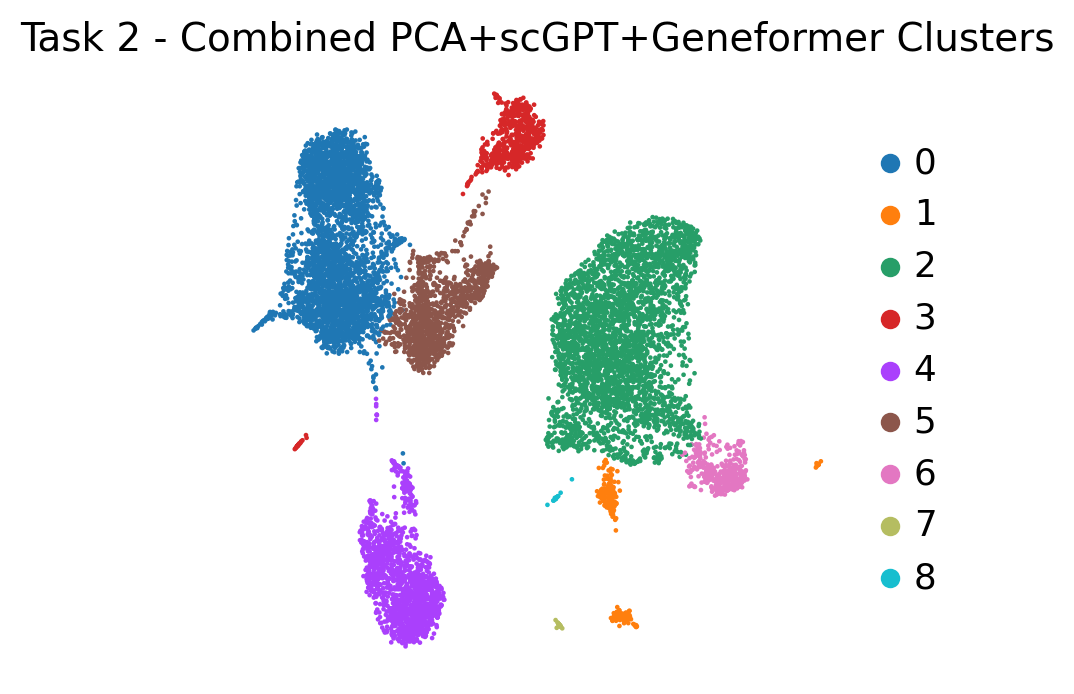

Saved: /content/drive/MyDrive/CS690_Assignment 1/Nehasri Eragandula_task2_submission.csv
   Id  Label
0   0      1
1   1      2
2   2      3
3   3      4
4   4      5


In [ ]:
# ---- Combined UMAP + Task 2 submission ----
sc.tl.umap(adata_combined, min_dist=0.5, spread=1.0, random_state=42)
sc.pl.umap(adata_combined, color="leiden_combined_final", title="Task 2 - Combined PCA+scGPT+Geneformer Clusters",
           legend_loc="right margin", frameon=False, show=True)

combined_labels_1based = adata_combined.obs["leiden_combined_final"].astype(int).to_numpy() + 1
task2_submission = pd.DataFrame({"Id": np.arange(adata.n_obs), "Label": combined_labels_1based})
task2_submission_path = os.path.join(ASSIGNMENT_DIR, f"{NAME}_task2_submission.csv")
task2_submission.to_csv(task2_submission_path, index=False)
print("Saved:", task2_submission_path)
print(task2_submission.head())


In [ ]:
print(adata_combined.obs["leiden_combined_final"].nunique())

9


## Task 1.2 — UCE (Universal Cell Embedding) — attempted, not completed

UCE was attempted as the third suggested foundation model but could not be completed
within the assignment timeline:
1. Original repository (snap-stanford/UCE): checkpoints are distributed via Figshare;
   repeated downloads returned empty/404 responses.
2. HuggingFace mirror (perturblab/uce-33-layer): avoided Figshare, but installing
   perturblab altered pandas/anndata versions, breaking sc.read_h5ad() with
   TypeError: StringDtype.__init__() got an unexpected keyword argument 'na_value'.

The intended code is included below as comments to document the approach.

In [1]:
# UCE_EMB_PATH = os.path.join(ASSIGNMENT_DIR, "uce_cell_embeddings.npy")
# if os.path.exists(UCE_EMB_PATH):
#     uce_embeddings = np.load(UCE_EMB_PATH)
# else:
#     !pip install -q perturblab huggingface_hub
#     from perturblab.model.uce import UCEModel
#     uce_model = UCEModel.from_pretrained("perturblab/uce-33-layer")
#     adata_uce = adata.copy()
#     result = uce_model.predict_embeddings(data=adata_uce, species="human", batch_size=16)
#     uce_embeddings = result["cell_embeddings"]
#     np.save(UCE_EMB_PATH, uce_embeddings)